# Pilotage énergétique par RL – 2. Le simulateur et les règles de référence

Avant d'entraîner un agent, il faut deux choses : un **simulateur** crédible de la maison, et des **points de comparaison**. Un agent RL ne vaut que s'il fait mieux qu'une règle simple qu'un installateur pourrait écrire.

Le code est dans `energy_env.py` (classe `Maison` pour la physique, `MaisonEnv` pour l'interface Gymnasium, et les trois règles).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from dataclasses import asdict
from energy_env import Maison, Params, charger_donnees, simuler, bilan, REGLES, PRIX
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

df = charger_donnees(); m = Maison(df)
pd.Series(asdict(Params()), name="valeur").to_frame()

,valeur
ballon_kwh,7.000
ballon_kw,3.000
pertes_h,0.005
batt_kwh,5.000
batt_kw,2.500
rendement,0.950
penalite_eur_kwh,3.000
horizon_pv,6.000
securite_kwh,1.000


## 1. Ce que simule chaque heure

1. Le **besoin d'eau chaude** réel de l'heure (sous-compteur 3) est prélevé dans le ballon. Si le ballon ne suffit pas, l'énergie manquante est comptée comme « eau froide ».
2. Si le pilote a décidé de **chauffer**, la résistance de 3 kW remplit le ballon, sans dépasser sa capacité. Sous 1 kWh, une **sécurité de thermostat** force la chauffe, quel que soit le pilote : c'est le cas sur un vrai ballon, et ça met tous les pilotes à égalité.
3. Le **solaire** couvre d'abord la maison. Le surplus va dans la **batterie**, et ce qui reste part sur le réseau sans rémunération (hypothèse : autoconsommation sans revente).
4. Selon le **mode de batterie** choisi :
   - *autoconsommation* : elle se décharge pour couvrir le déficit ;
   - *charger* : elle se remplit aussi depuis le réseau ;
   - *conserver* : elle ne se décharge pas.
5. Le reste est **acheté** au prix Tempo de l'heure.

In [2]:
# une heure de démonstration : un jour rouge de janvier à 8 h, ballon à moitié plein, batterie pleine
t = int(np.where((df.tempo == "rouge") & (df.index.hour == 8) & (df.index.month == 1))[0][0])
print(df.index[t], "| couleur :", df.tempo.iloc[t], "| prix :", m.prix[t], "€/kWh | besoin eau chaude :", round(float(m.ecs[t]), 2), "kWh")
for nom, (chauffe, mode) in {"ne rien chauffer, batterie en autoconsommation": (0, 0), "chauffer, batterie conservée": (1, 2)}.items():
    b, s, info = m.pas(t, 3.5, 5.0, chauffe, mode)
    print(f"- {nom} : achat {info['achat']:.2f} kWh, coût {info['cout']:.2f} €, ballon après {b:.2f} kWh, batterie après {s:.2f} kWh")

2015-01-05 08:00:00 | couleur : rouge | prix : 0.7295 €/kWh | besoin eau chaude : 1.05 kWh
- ne rien chauffer, batterie en autoconsommation : achat 0.00 kWh, coût 0.00 €, ballon après 2.44 kWh, batterie après 3.12 kWh
- chauffer, batterie conservée : achat 4.79 kWh, coût 3.49 €, ballon après 5.43 kWh, batterie après 5.00 kWh


**Lecture.** Le 5 janvier 2015 à 8 h, jour rouge (0,7295 €/kWh), il faut 1,05 kWh d'eau chaude. Si le pilote ne chauffe pas et laisse la batterie couvrir la maison, il n'achète rien. S'il chauffe en gardant la batterie, il achète 4,79 kWh, soit 3,49 € pour une seule heure. Un mauvais choix à la mauvaise heure coûte cher : c'est ce que l'agent doit apprendre à éviter.

## 2. Les trois règles de référence

| Règle | Ballon | Batterie |
|---|---|---|
| **Thermostat** (la maison réelle) | se réchauffe dès que de l'eau est tirée | autoconsommation |
| **Contacteur heures creuses** (le standard) | chauffe de 22 h à 6 h (plus la sécurité sous 1 kWh) | autoconsommation |
| **Règle experte** (écrite avec le tarif en tête) | heures creuses + surplus solaire > 1,5 kW, évite les heures pleines rouges | chargée la nuit avant un jour blanc ou rouge, gardée pour les heures pleines |

In [3]:
def saison(s):
    pos = np.where(df.saison == s)[0]; return int(pos[0]), int(pos[-1]) + 1

res, traces = {}, {}
for s in ["2021-2022", "2022-2023"]:
    a, b = saison(s)
    for nom, regle in REGLES.items():
        r = simuler(m, a, b, regle); traces[(s, nom)] = r
        res[(s, nom)] = bilan(r, m)
tab = pd.DataFrame(res).T
tab.index.names = ["saison", "règle"]
ref = tab.xs("thermostat", level="règle").facture_eur
tab["gain_vs_thermostat_%"] = (100 * (1 - tab.facture_eur / ref.reindex(tab.index.get_level_values(0)).values)).round(1)
tab

facture_eur  achat_kwh  rouge_hp_kwh  autoconso_pct  \
saison    règle                                                                 
2021-2022 thermostat           1301.6     6432.0         464.3           87.6   
          heures_creuses       1224.4     6611.0         358.8           80.7   
          experte              1127.6     6414.0         258.0           86.9   
2022-2023 thermostat           1411.2     7213.0         438.1           87.0   
          heures_creuses       1329.2     7320.0         341.2           81.6   
          experte              1252.2     7218.0         249.6           85.5   

                          eau_froide_h  eau_froide_kwh  gain_vs_thermostat_%  
saison    règle                                                               
2021-2022 thermostat               0.0            0.00                   0.0  
          heures_creuses          25.0            1.53                   5.9  
          experte                 15.0            0.81                  13.4  
2022-2023 thermostat               0.0            0.00                   0.0  
          heures_creuses          10.0            0.21                   5.8  
          experte                  8.0            0.16                  11.3

**Lecture (saison test 2022-2023).**

| Règle | Facture | Gain vs thermostat |
|---|---|---|
| Thermostat (maison réelle) | 1 411 € | référence |
| Contacteur heures creuses | 1 329 € | −5,8 % |
| Règle experte | 1 252 € | −11,3 % |

- **Où se fait le gain :** l'achat en heures pleines rouges passe de 438 à 250 kWh avec la règle experte.
- **Ce que coûte le contacteur :** l'autoconsommation solaire baisse (81,6 % contre 87 %), car le ballon est déjà plein quand le soleil arrive.
- **Confort :** les pannes d'eau chaude restent marginales, 8 à 25 heures par an pour moins de 2 kWh manquants.
- **Ce que l'agent doit battre :** la règle experte, 1 128 € sur la validation et 1 252 € sur le test.

## 3. Quatre jours de décembre 2022, dont trois jours rouges d'affilée

Couleurs : {'2022-12-11': 'bleu', '2022-12-12': 'rouge', '2022-12-13': 'rouge', '2022-12-14': 'rouge'}


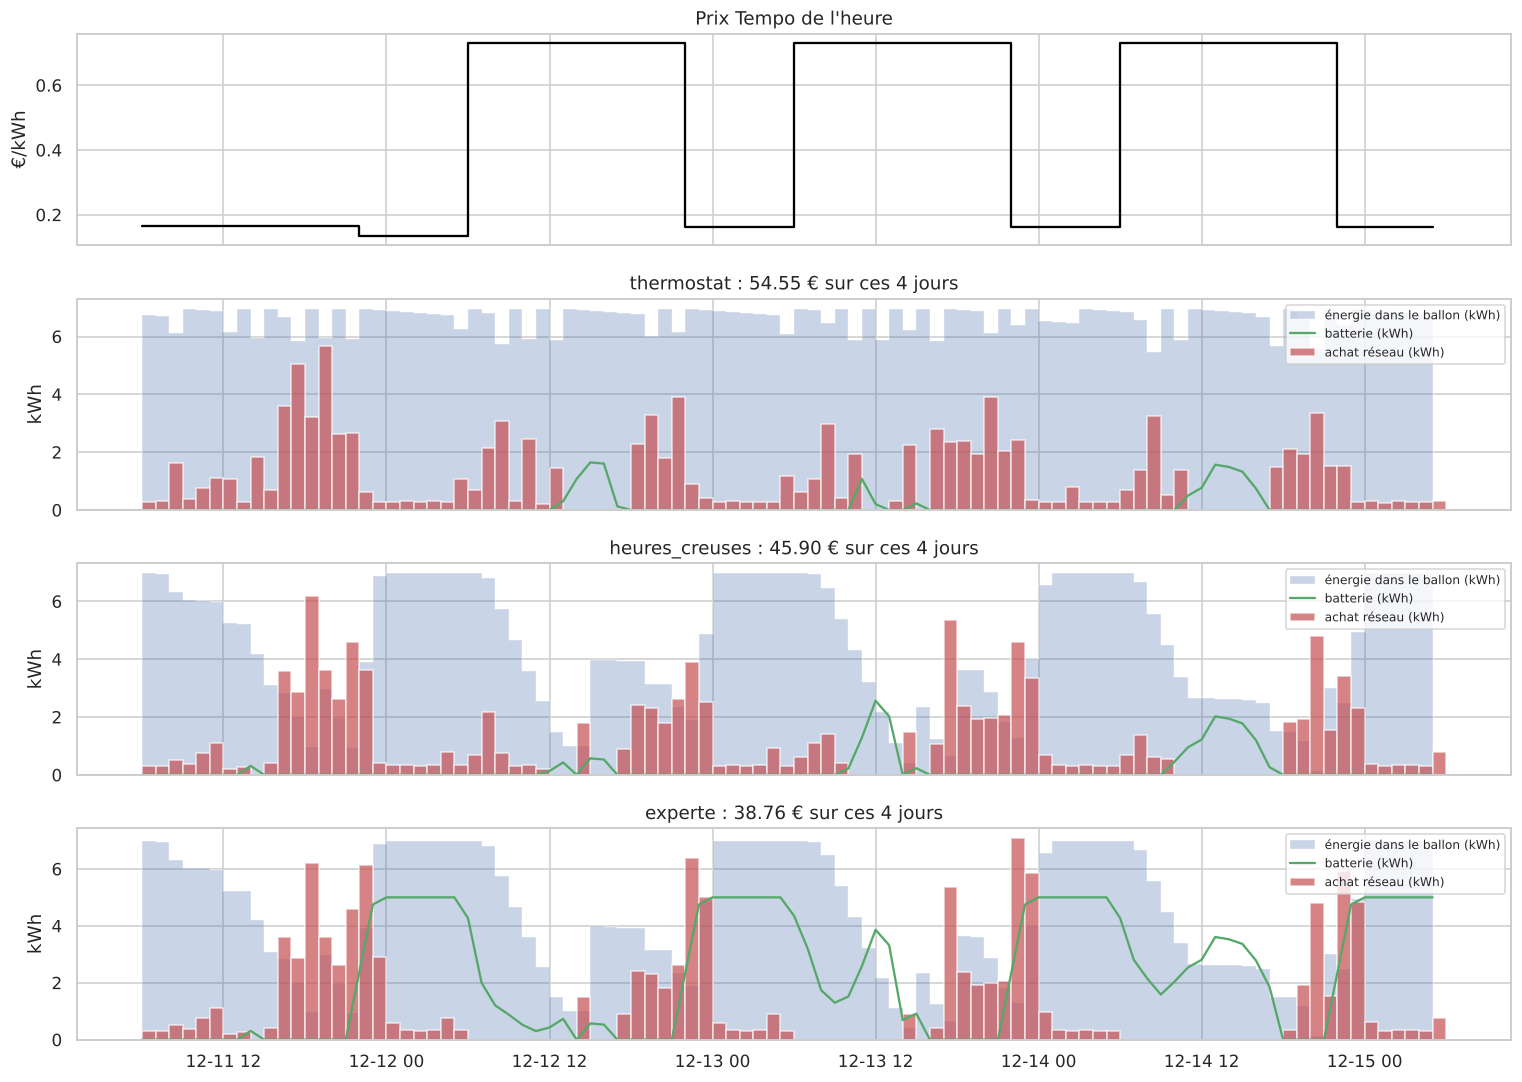

In [4]:
a, b = saison("2022-2023")
cal = pd.read_csv("../../data/tempo_couleurs.csv", parse_dates=["date"]).set_index("date").couleur
debut = pd.Timestamp("2022-12-11")
print("Couleurs :", {str(d.date()): cal[d] for d in pd.date_range(debut, periods=4)})
fen = slice(debut + pd.Timedelta(hours=6), debut + pd.Timedelta(days=4, hours=5))
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
d = df.loc[fen]
axes[0].step(d.index, d.prix, where="post", color="black"); axes[0].set(ylabel="€/kWh", title="Prix Tempo de l'heure")
for ax, nom in zip(axes[1:], ["thermostat", "heures_creuses", "experte"]):
    r = traces[("2022-2023", nom)].loc[fen]
    ax.fill_between(r.index, r.ballon, step="post", alpha=.3, label="énergie dans le ballon (kWh)")
    ax.bar(r.index, r.achat, width=1 / 24, align="edge", color="#c44e52", alpha=.7, label="achat réseau (kWh)")
    ax.plot(r.index, r.soc, color="#55a868", label="batterie (kWh)")
    ax.set(title=f"{nom} : {r.cout.sum():.2f} € sur ces 4 jours", ylabel="kWh"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.** Sur ces 4 jours (un bleu puis trois rouges), la facture est de 54,55 € avec le thermostat, 45,90 € avec le contacteur et 38,76 € avec la règle experte.
- **Ce que fait l'expert :** il remplit la batterie la nuit (courbe verte à 5 kWh à 6 h) et chauffe l'eau en heures creuses.
- **Ce qui reste :** 35,1 kWh achetés en heures pleines rouges, surtout le soir (26,1 kWh entre 18 h et 22 h), une fois la batterie vidée. Garder la batterie pour le soir n'y changerait rien : de 6 h à 22 h, le prix est le même. Le seul levier serait une batterie plus grande. La marge laissée par l'expert se mesure donc avec l'optimum théorique (notebook 3).

## 4. Où part l'argent ?

In [5]:
lignes = []
for nom in REGLES:
    r = traces[("2022-2023", nom)]; d = df.loc[r.index]
    cle = d.tempo + np.where(d.hc, " HC", " HP")
    lignes.append(r.cout.groupby(cle).sum().rename(nom))
cout = pd.concat(lignes, axis=1).round(0)
cout.loc["total"] = cout.sum()
cout

,thermostat,heures_creuses,experte
tempo,,,
blanc HC,45.0,74.0,94.0
blanc HP,160.0,125.0,92.0
bleu HC,215.0,386.0,395.0
bleu HP,651.0,459.0,435.0
rouge HC,20.0,36.0,54.0
rouge HP,320.0,249.0,182.0
total,1411.0,1329.0,1252.0


**Lecture.** Le poste qui change le plus est l'heure pleine rouge : 320 € avec le thermostat, 249 € avec le contacteur, 182 € avec la règle experte, sur 22 jours seulement. Les heures pleines bleues pèsent aussi (651 € avec le thermostat contre 435 € avec l'expert), car on y déplace la chauffe vers la nuit. En contrepartie, les heures creuses montent (bleu HC de 215 à 395 €) : on achète plus la nuit, mais moins cher.